# Intro

Check the readme files in the folder to learn how to run scans and use defaults vs specify parameters

# Initialize (Run everything in this section before starting experiments)

In [ ]:
## please keep the old lines and add new lines with minimal comments, so we can easily identify the scope of each test.
cfg_file = '2026_06_08_smpd_v2_run30.yml'
expt_path = 'C:\\_Data\\SMPD\\2026_06_01_Yuvi_v2_run30'

max_t1 = 250 #

## Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import copy
from IPython.display import clear_output

#np.set_printoptions(legacy="1.25")
from qick import QickConfig

from slab_qick_calib.exp_handling.instrumentmanager import InstrumentManager
import slab_qick_calib.experiments as meas
from slab_qick_calib.experiments.jpa import turn_on_jpa, turn_off_jpa
from slab_qick_calib.calib import qubit_tuning, measure_func
from slab_qick_calib.calib.time_tracking import time_tracking
from slab_qick_calib.analysis import qubit_params, fitres
from slab_qick_calib.helpers import qick_check, config, handy, rfboard
from fridge.bluefors import BlueforsClient
from fridge.credentials import BLUEFORS_HOST, BLUEFORS_PORT, BLUEFORS_API_KEY

%load_ext autoreload
%autoreload 2

# Set color palette and font size
handy.config_figs()
%config InlineBackend.figure_format = 'png'

import matplotlib 
matplotlib.rcParams['path.simplify'] = True
matplotlib.rcParams['path.simplify_threshold'] = 0.1
matplotlib.rcParams['agg.path.chunksize'] = 10000


## Set up new config 
Set to variables to True when setting up a new experiment config file. 

Note: make sure you set your ADC/DAC channels correctly. This code does not automatically fill in the ADC/DAC into your configuration file, so you should check yourself to make sure these values are correct. 

There are several elements that you may want to customize based on your readout parameters and coherence times. Check readme file config_manual.md

In [ ]:
# Set to false if you aren't creating a new one (so set to false as soon as you run it)
new_config = False
new_folder = True

nqubits = 2 # For SMPD, we have 1 qubit per chip, but it's coupled to 2 resonators, so we can treat it as a 2 qubit system for the purposes of the config file.
rfsoc_alias = 'smpd_qick'
t1_guess = 20 
ip = '192.168.137.93' # ip address of name server that rfsoc is connected to 
import os

configs_dir = os.path.join(os.getcwd(),'../../', 'configs')

cfg_file_path = os.path.join(configs_dir, cfg_file)
images_dir = os.path.join(expt_path, 'images')
data_dir = os.path.join(expt_path, 'data')
summary_dir = os.path.join(images_dir, 'summary')

if new_config or new_folder:
    if new_config:
        config.init_config(cfg_file_path, nqubits, type='full', aliases=rfsoc_alias, t1=t1_guess, ip=ip)
        config.init_model_config(cfg_file_path, nqubits)

    if not os.path.exists(expt_path):
        os.makedirs(expt_path)
        os.mkdir(images_dir)
        os.mkdir(summary_dir)
        os.mkdir(data_dir)

print('Data will be stored in', expt_path)

## Connect to RFSoC
Before running first cell, make sure a nameserver is running on the network, the Qick board is connected to it, and the ip address listed below matches that of the nameserver. 

You just need to run the first cell, then should be able to run any other cell in whatever order. 

If you need to restart the RFSoC, you should reconnect it to the nameserver and rerun this. 

In [ ]:
# Results config file
cfg_path = os.path.join(os.getcwd(),'../..', 'configs', cfg_file)
auto_cfg = config.load(cfg_path)

# print(auto_cfg)

# Connect to instruments

auto_cfg = config.load(cfg_path)

im = InstrumentManager(ns_address=auto_cfg['aliases']['ip'], port=9090)
soc = im[auto_cfg['aliases']['soc']]
soccfg = QickConfig(soc.get_cfg())

print(soccfg)
# Switch all shared RF channels to qubit 2's settings

# rfboard.get_active_rf_state(auto_cfg, "dac_qubit")          # one channel type
# rfboard.get_active_rf_state(auto_cfg, "adc", ch=2)          # one channel entry

cfg_dict = {'soc': soccfg, 'expt_path': expt_path, 'cfg_file': cfg_path, 'im': im}

In [ ]:
bf = BlueforsClient(
    host=BLUEFORS_HOST,
    port=BLUEFORS_PORT,
    api_key=BLUEFORS_API_KEY,
    verify_ssl=False,
)
print(f"MXC: {bf.get_mxc_temperature()*1000:.2f} mK")

# Time of Flight (TOF)

TOF measures the time it takes for the signal to run through the wires. It will give us the time in clock ticks that we should wait to make a measurements 

 Use this to set trig_offset in config file

Activated qubit 1: ADC ch 1 (fc=8200, bw=100, bandpass), DAC-ro ch 1 (fc=8200, bw=100, bandpass), DAC-qb ch 3 (fc=4300, bw=500, bandpass), DC bias ch 1 (val=0.03 V)


  0%|          | 0/50000 [00:00<?, ?it/s]

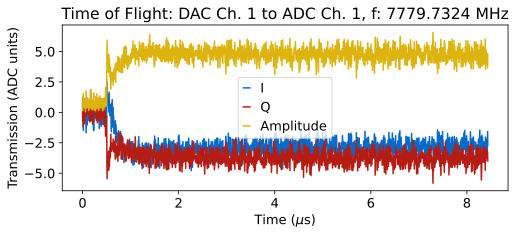

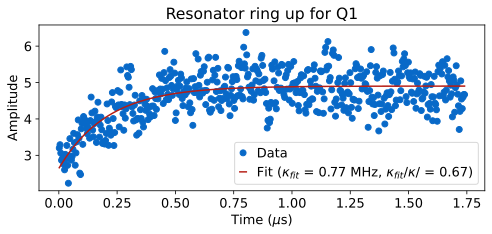

In [126]:
qi = 1
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
rfboard.get_active_rf_state(auto_cfg)      

tof=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi, params={'use_readout':True, 'readout_length':8, 'rounds':50000})

# Set frequency of choice and readout length (up to 13 us for standard ZCU216 firmware, readout)
#tof=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi,params={'readout_length':13})#,)


In [ ]:
tof_e=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi, params={'use_readout':True, 'readout_length':6, 'rounds':5000, 'check_e':True})

  0%|          | 0/50000 [00:00<?, ?it/s]

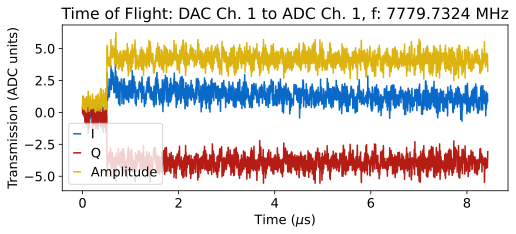

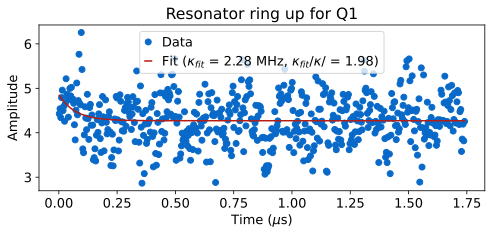

In [125]:
tof_e2=meas.ToFCalibrationExperiment(cfg_dict=cfg_dict, qi=qi, params={'use_readout':True, 'readout_length':8, 'rounds':50000, 'check_e':True})

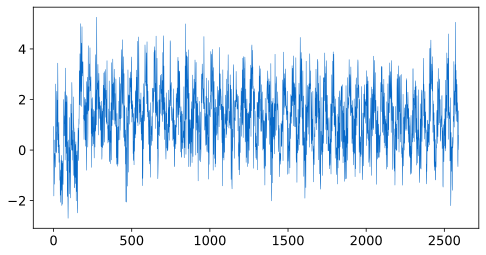

In [123]:

plt.figure()
plt.plot(tof_e.data['i'], linewidth=0.5)

{'xpts': array([0.00000000e+00, 3.25520833e-03, 6.51041667e-03, ...,
        8.42773438e+00, 8.43098958e+00, 8.43424479e+00]),
 'i': array([-0.3703    , -1.0086    , -1.09826667, ...,  1.4369    ,
         1.4968    ,  0.83576667]),
 'q': array([-0.34983333, -0.0399    , -0.96573333, ..., -4.61243333,
        -3.4594    , -4.49766667]),
 'amps': array([0.50941678, 1.00938891, 1.46247412, ..., 4.8310685 , 3.76933132,
        4.5746597 ]),
 'phases': array([-2.3846075 , -3.10205349, -2.42031834, ..., -1.26879765,
        -1.16244189, -1.38706961]),
 't_min': 0.5971,
 'ring_up_fit': {'popt': array([ 1.02394675, 14.75818105,  4.20001934]),
  'pcov': array([[8.20620707e-02, 1.18353024e+00, 1.48926124e-05],
         [1.18353024e+00, 3.69414295e+01, 5.39298087e-02],
         [1.48926124e-05, 5.39298087e-02, 9.32031666e-04]]),
  'mask': array([False, False, False, ..., False, False, False])},
 'ring_up_amplitude': 1.0239467521598358,
 'ring_up_rate': 14.758181049979148,
 'ring_up_offset': 4.20

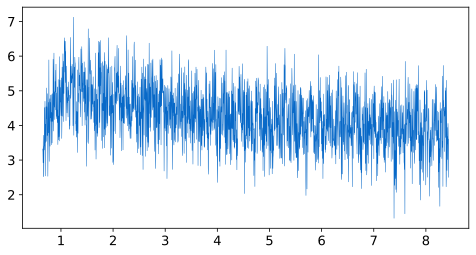

In [138]:
plt.figure()
# plt.plot(tof_e2.data['i'], linewidth=0.5)
# plt.plot(tof.data['i'], linewidth=0.5)
inds = np.where(tof_e.data['xpts']>0.65)[0]
plt.plot(tof_e.data['xpts'][inds],tof_e2.data['i'][inds]-tof.data['i'][inds], linewidth=0.5)
#plt.plot(, linewidth=0.5)

## Set trig_offset to point where signal has appeared, usually around 300-500 ns

In [ ]:
tof_data = tof.analyze()
print(tof_data['xpts'][np.argmin(abs(tof_data['amps']-max(tof_data['amps'])/2))])

In [ ]:
qubit_list=[0]
trig_offset = tof_data['xpts'][np.argmin(abs(tof_data['amps']-max(tof_data['amps'])/2))]
for qi in qubit_list: 
    auto_cfg = config.update_readout(cfg_path, 'trig_offset', trig_offset, qi)

# Resonator Spectroscopy 

Run resonator spectroscopy for all resonators by choosing a large frequency scan to look over. The scan will then find the different resonators and fill in the config file with their respective frequencies. In the autocalibration, there will be a finer sweep of each resonator to more accurately find its frequency. The frequencies are saved in <code>auto_cfg.device.readout.frequency</code>

In [ ]:
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)


In [ ]:
qi = 1
# auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
# rfboard.get_active_rf_state(auto_cfg)      

auto_cfg = config.load(cfg_path)
update=False # Set to true if you want to update the config file with the new resonance values

# comment out one of these 
# qubit_list = np.arange(6)
ifauto = False

if ifauto:
    # Fully automated, using previous fit to kappa to set span
    rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':10,'reps':5000})
    gain = auto_cfg.device.readout.gain[qi]
else:
    # Manually set the span and gain v
    gain = 0.01
    rspec = meas.ResSpec(cfg_dict, qi=qi, params={'span':40, 'gain':gain, 'reps':2000, 'expts':500,'pulse_e':True,'pulse_g':True})

if update: rspec.update()

In [ ]:
vals

In [ ]:
S21_db = 20 * np.log10(rspec.data['amps'])
phases_unwrapped = rspec.data['phase_fix']
phases_unwrapped -= np.polyval(np.polyfit(rspec.data['xpts'][1:-1][:100], phases_unwrapped[:100], deg=1), rspec.data['xpts'][1:-1]) # remove linear background from phase data

S21 = rspec.data['amps'][1:-1] * np.exp(1j * (phases_unwrapped))
# only fit to the inner third of points to avoid edge effects
one_third = len(rspec.data['xpts'][1:-1]) // 3
vals = fitres.finefit(rspec.data['xpts'][1:-1][one_third:-one_third],S21[one_third:-one_third],[7780.5])
S21_fit = fitres.resfunc3(rspec.data['xpts'][1:-1][one_third:-one_third],vals[0],vals[1],vals[2],vals[3],vals[4],vals[5])

# print out the fit results
print(f"Resonance frequency: {vals[0]:.3f} MHz")
print(f"linewidth: {vals[0]/vals[1]:.3f} MHz")

plt.figure()
plt.plot(rspec.data['xpts'], S21_db)
plt.plot(rspec.data['xpts'][1:-1][one_third:-one_third], 20 * np.log10(np.abs(S21_fit)), label='fit')
plt.xlabel('Frequency (MHz)')
plt.ylabel('|S21| (dB)')
plt.title(f'VNA scan qubit {qi}')

plt.figure()
plt.plot(rspec.data['xpts'][1:-1], phases_unwrapped)
plt.plot(rspec.data['xpts'][1:-1][one_third:-one_third], np.unwrap(np.angle(S21_fit)), label='fit')
plt.xlabel('Frequency (MHz)')
plt.ylabel('Phase (degrees)')
plt.title(f'VNA scan qubit {qi}')

plt.figure()
plt.plot(S21.real, S21.imag,marker='.')
plt.plot(S21_fit.real, S21_fit.imag, label='fit')
plt.plot(S21_fit.real, S21_fit.imag)
plt.axis('equal')

## JPA Tuning

This replaces the old notebook-local DC-bias scan and threaded CW tone helper with the class-based JPA experiments in `experiments/jpa`.


In [160]:
import importlib
import time
import slab_qick_calib.experiments as meas
importlib.reload(meas)

qi = 1
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
auto_cfg = config.load(cfg_path)

WASTE_RESONANCE_MHZ = 7780.828
PUMP_DETUNING_MHZ = 2.0
PUMP_DETUNING_SIGN = +1
PUMP_FREQ_MHZ = WASTE_RESONANCE_MHZ + PUMP_DETUNING_SIGN * PUMP_DETUNING_MHZ

PUMP_CH = 13
PUMP_NQZ = 2
PUMP_IF_MHZ = 400.0
PUMP_MIXER_FREQ_MHZ = PUMP_FREQ_MHZ - PUMP_IF_MHZ
PUMP_ATTEN1_DB = 15
PUMP_ATTEN2_DB = 0
PUMP_FILTER_BW_MHZ = 1000.0
PUMP_FILTER_TYPE = "bandpass"
PUMP_GAIN_GUESS = 0.03

JPA_DC_CH = auto_cfg.hw.soc.dacs.flux.dc_ch[qi]
JPA_OFF_BIAS_V = 0.0
JPA_ON_BIAS_V = 117e-3
DC_SETTLE_S = 0.25

JPA_RSPEC_UPDATE = True  # set True to write hw.soc.dacs.jpa into cfg_path after the scan

print(f"Waste resonance: {WASTE_RESONANCE_MHZ:.3f} MHz")
print(f"Pump frequency: {PUMP_FREQ_MHZ:.3f} MHz")
print(f"Pump mixer frequency: {PUMP_MIXER_FREQ_MHZ:.3f} MHz")
print(f"Pump attenuation: attn1={PUMP_ATTEN1_DB} dB, attn2={PUMP_ATTEN2_DB} dB")
print(f"JPA DC bias center: {JPA_ON_BIAS_V * 1e3:.1f} mV")
print(f"YAML update enabled: {JPA_RSPEC_UPDATE}")


<module 'slab_qick_calib.experiments' from 'C:\\_Lib\\python\\slab_qick_calib\\experiments\\__init__.py'>
C:\_Lib\python\slab_qick_calib\experiments
imported slab_qick_calib.experiments.general.qick_experiment
imported slab_qick_calib.experiments.general.qick_experiment_2q
imported slab_qick_calib.experiments.general.qick_flux_experiment
imported slab_qick_calib.experiments.general.qick_program
C:\_Lib\python\slab_qick_calib\experiments\flux
imported slab_qick_calib.experiments.flux.pulse_probe_spectroscopy_flux
imported slab_qick_calib.experiments.flux.qubit_spec_predistorted
imported slab_qick_calib.experiments.flux.rabi_flux
imported slab_qick_calib.experiments.flux.resonator_spectroscopy_flux
imported slab_qick_calib.experiments.flux.single_shot_flux
imported slab_qick_calib.experiments.flux.t1_cont_flux
imported slab_qick_calib.experiments.flux.t1_fastflux_loop
imported slab_qick_calib.experiments.flux.t1_predistorted
imported slab_qick_calib.experiments.flux.t1_predist_fastflux
C

### JPA DC Bias Scan

This is the class-based version of the old scan over `0.100` to `0.125` V. If `JPA_RSPEC_UPDATE=True`, it writes the current JPA pump/DC settings into `hw.soc.dacs.jpa` with the active values in entry `1`.


  0%|          | 0/20 [00:00<?, ?it/s]

[JPA bias] ch 1: set 105.000 mV, read 105.000 mV


  5%|▌         | 1/20 [00:03<01:11,  3.75s/it]

[JPA bias] ch 1: set 106.316 mV, read 106.316 mV


 10%|█         | 2/20 [00:07<01:07,  3.75s/it]

...

[JPA bias] ch 1: set 128.684 mV, read 128.689 mV


 95%|█████████▌| 19/20 [01:11<00:03,  3.76s/it]

[JPA bias] ch 1: set 130.000 mV, read 130.005 mV


100%|██████████| 20/20 [01:15<00:00,  3.76s/it]


Updated hw.soc.dacs.jpa in c:\_Lib\python\slab_qick_calib\notebooks\SMPDs\..\..\configs\2026_06_08_smpd_v2_run30.yml: pump ch 13, pump 7782.828 MHz, gain 0.03, DC ch 1, DC 0.117 V


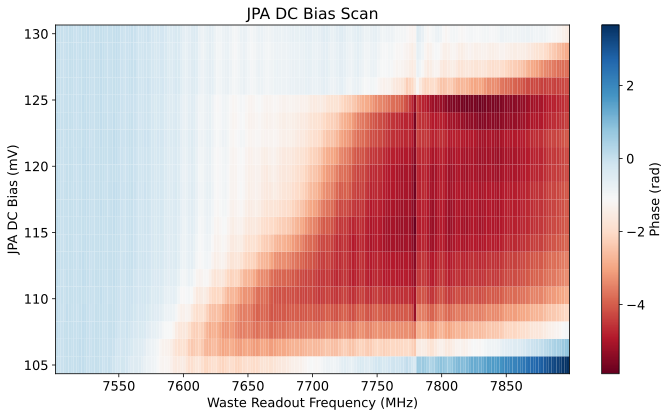

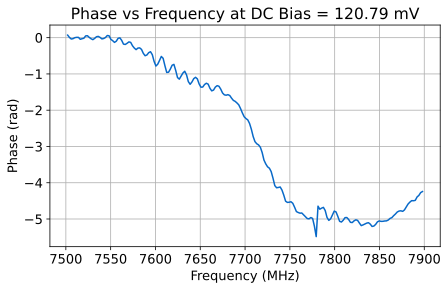

In [161]:
jpa_bias = meas.JPABiasScan(
    cfg_dict,
    qi=qi,
    params={
        "center": 7700,
        "span": 400.0,
        "expts": 200,
        "gain": gain,
        "reps": 1000,
        "rounds": 1,
        "dc_start": 0.105,
        "dc_stop": 0.130,
        "expts_dc": 20,
        "bias_chan": JPA_DC_CH,
        "jpa_dc_val": JPA_ON_BIAS_V,
        "dc_settle": DC_SETTLE_S,
        "reset_bias_after": True,
        "reset_bias": JPA_OFF_BIAS_V,
        "pump_ch": PUMP_CH,
        "pump_nqz": PUMP_NQZ,
        "pump_freq_mhz": PUMP_FREQ_MHZ,
        "pump_mixer_freq_mhz": PUMP_MIXER_FREQ_MHZ,
        "pump_attn1_db": PUMP_ATTEN1_DB,
        "pump_attn2_db": PUMP_ATTEN2_DB,
        "pump_filter_bw_mhz": PUMP_FILTER_BW_MHZ,
        "pump_filter_type": PUMP_FILTER_TYPE,
        "pump_gain": PUMP_GAIN_GUESS,
        "rspec_update": JPA_RSPEC_UPDATE,
    },
)

dc_index = min(12, len(jpa_bias.data["dc_biases_mv"]) - 1)
phase_map = jpa_bias.data.get("phase_fix_corrected", jpa_bias.data.get("phases_corrected", jpa_bias.data["phases"]))
freq_for_phase = jpa_bias.data.get("freq_phase_mhz", jpa_bias.data["freq_mhz"])

plt.figure(figsize=(7, 4))
plt.plot(freq_for_phase, phase_map[dc_index])
plt.xlabel("Frequency (MHz)")
plt.ylabel("Phase (rad)")
plt.title(f"Phase vs Frequency at DC Bias = {jpa_bias.data['dc_biases_mv'][dc_index]:.2f} mV")
plt.grid(True)
plt.show()


#### old code

In [ ]:
q1=1
dc_vals = np.linspace(0.1, 0.125, 20)  # V
phases_2d = []

for dc_val in dc_vals:
    rfboard.set_dc_bias(q1, soc, auto_cfg, dc_val=dc_val)

    rspec_dc = meas.ResSpec(
        cfg_dict,
        qi=q1,
        go=False,
        params={
            'gain': gain,
            'reps': 1000,
            'center': 7600,
            'span': 500,
            'expts': 200
        }
    )

    rspec_dc.acquire()
    rspec_dc.analyze()

    # correct the phase data by removing a linear background
    phases_unwrapped = rspec_dc.data['phase_fix']
    num_xpts = len(rspec_dc.data['xpts'][1:-1])

    phases_unwrapped -= np.polyval(
        np.polyfit(
            rspec_dc.data['xpts'][1:-1][:int(num_xpts/10)],
            phases_unwrapped[:int(num_xpts/10)],
            deg=1
        ),
        rspec_dc.data['xpts'][1:-1]
    )  # remove linear background from phase data

    phases_2d.append(phases_unwrapped)

rfboard.set_dc_bias(q1, soc, auto_cfg, dc_val=0.0)  # reset bias

phases_2d = np.array(phases_2d)
xpts = rspec_dc.data['xpts'][1:-1]

plt.figure(figsize=(10, 6))
plt.pcolormesh(
    xpts,
    dc_vals * 1e3,
    phases_2d,
    shading="auto",
    cmap="RdBu"
)
plt.colorbar(label='Phase (rad)')
plt.xlabel('Frequency (MHz)')
plt.ylabel('DC Bias (mV)')

### JPA Fine Tuning

This measures the waste baseline with the pump off, then scans pump DAC gain vs DC bias. If `JPA_RSPEC_UPDATE=True`, the best pump gain and DC bias are written into `hw.soc.dacs.jpa`.


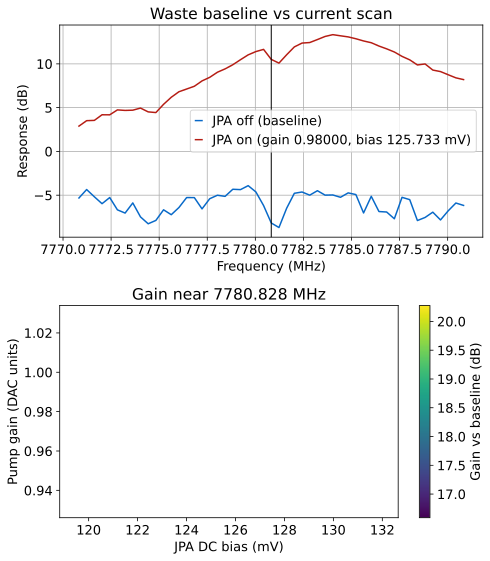

100%|██████████| 1/1 [00:09<00:00,  9.31s/it]


JPA parked at best point: bias=125.733 mV, pump gain=0.98000
Updated hw.soc.dacs.jpa in c:\_Lib\python\slab_qick_calib\notebooks\SMPDs\..\..\configs\2026_06_08_smpd_v2_run30.yml: pump ch 13, pump 7782.828 MHz, gain 0.98, DC ch 1, DC 0.125733 V
Error saving dataset 'baseline': Object of type ndarray is not JSON serializable


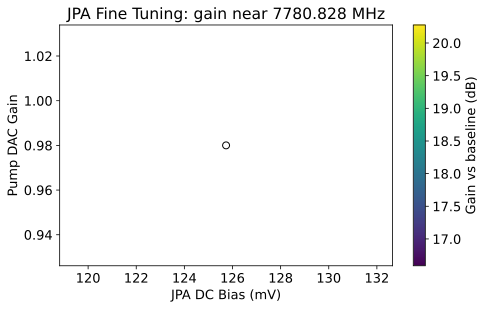

Maximum gain near resonance: 18.43 dB
Optimal pump frequency: 7782.828 MHz
Optimal pump mixer frequency: 7382.828 MHz
Optimal pump DAC gain: 0.98000
Optimal DC bias: 125.733 mV


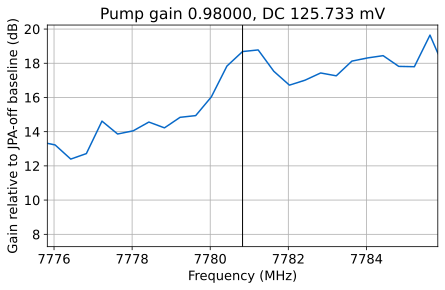

JPA DC bias parked at 125.733 mV


In [162]:
pump_gains = np.linspace(0.98, 0.98, 1)
dc_biases_v = np.linspace(125.733e-3, 125.733e-3, 1)

jpa_fine = meas.JPAFineTuning(
    cfg_dict,
    qi=qi,
    params={
        "waste_freq_mhz": WASTE_RESONANCE_MHZ,
        "center": WASTE_RESONANCE_MHZ,
        "span": 20.0,
        "expts": 51,
        "gain": 0.01,
        "length": 10,
        "reps": 10000,
        "rounds": 1,
        "pump_ch": PUMP_CH,
        "pump_nqz": PUMP_NQZ,
        "pump_freq_mhz": PUMP_FREQ_MHZ,
        "pump_mixer_freq_mhz": PUMP_MIXER_FREQ_MHZ,
        "pump_attn1_db": PUMP_ATTEN1_DB,
        "pump_attn2_db": PUMP_ATTEN2_DB,
        "pump_filter_bw_mhz": PUMP_FILTER_BW_MHZ,
        "pump_filter_type": PUMP_FILTER_TYPE,
        "pump_gains": pump_gains,
        "dc_biases_v": dc_biases_v,
        "bias_chan": JPA_DC_CH,
        "off_bias": JPA_OFF_BIAS_V,
        "dc_settle": DC_SETTLE_S,
        "gain_window_mhz": 0.5,
        "rspec_update": JPA_RSPEC_UPDATE,
    },
)

print(f"Maximum gain near resonance: {jpa_fine.data['best_gain_db']:.2f} dB")
print(f"Optimal pump frequency: {jpa_fine.data['pump_freq_mhz']:.3f} MHz")
print(f"Optimal pump mixer frequency: {jpa_fine.data['pump_mixer_freq_mhz']:.3f} MHz")
print(f"Optimal pump DAC gain: {jpa_fine.data['best_pump_gain']:.5f}")
print(f"Optimal DC bias: {jpa_fine.data['best_dc_bias_mv']:.3f} mV")

best_i, best_j = jpa_fine.data["best_index"]
plt.figure(figsize=(7, 4))
plt.plot(jpa_fine.data["freq_mhz"], jpa_fine.data["gain_db"][best_i, best_j, :])
plt.axvline(WASTE_RESONANCE_MHZ, color="k", lw=1)
plt.xlim(WASTE_RESONANCE_MHZ - 5, WASTE_RESONANCE_MHZ + 5)
plt.xlabel("Frequency (MHz)")
plt.ylabel("Gain relative to JPA-off baseline (dB)")
plt.title(f"Pump gain {jpa_fine.data['best_pump_gain']:.5f}, DC {jpa_fine.data['best_dc_bias_mv']:.3f} mV")
plt.grid(True)
plt.show()

# Park only the DC bias here. Later experiments should read hw.soc.dacs.jpa and generate the pump in-program.
soc.rfb_set_bias(JPA_DC_CH, float(jpa_fine.data["best_dc_bias_v"]))
time.sleep(DC_SETTLE_S)
print(f"JPA DC bias parked at {jpa_fine.data['best_dc_bias_mv']:.3f} mV")


In [166]:
from slab_qick_calib.experiments.jpa.jpa_tone import get_jpa_state, set_periodic_tone
get_jpa_state(soc, auto_cfg)
set_periodic_tone(
    soc,
    soccfg,
    ch=PUMP_CH,
    freq_mhz=PUMP_FREQ_MHZ,
    gain=jpa_fine.data["best_pump_gain"],
    nqz=PUMP_NQZ,
    mixer_freq_mhz=PUMP_MIXER_FREQ_MHZ,
)

JPA state: pump ch 13 @ 7782.828 MHz, gain=0.98000 (recorded, not read back), DC bias ch 1 readback=30.003 mV (recorded=125.000 mV)


In [ ]:
from slab_qick_calib.experiments.jpa.jpa_tone import get_jpa_state, set_periodic_tone
get_jpa_state(soc, auto_cfg)
set_periodic_tone(
    soc,
    soccfg,
    ch=PUMP_CH,
    freq_mhz=PUMP_FREQ_MHZ,
    gain=0.0,
    nqz=PUMP_NQZ,
    mixer_freq_mhz=PUMP_MIXER_FREQ_MHZ)

JPA state: pump ch 13 @ 7782.828 MHz, gain=0.98000 (recorded, not read back), DC bias ch 1 readback=30.003 mV (recorded=125.000 mV)


In [ ]:
import h5py

# load most recent resonator spectroscopy data for qi1, file starts with resonator_spectroscopy_fine_qubit1
files = [f for f in os.listdir(expt_path +'\\data') if f.startswith('resonator_spectroscopy_fine_qubit1')]
files = sorted(files)
with h5py.File(expt_path +'\\data\\' + files[-1], 'r') as f:
    xpts = f['xpts'][:]
    amps = f['amps'][:]
    phases = f['phases'][:]
unwrapped = np.unwrap(phases)
polyfit = np.polyfit(xpts[:300],unwrapped[:300],1)
corrected = unwrapped - np.polyval(polyfit, xpts)
plt.plot(xpts, corrected)
plt.plot(xpts[:300], corrected[:300], 'r-')

S21 = amps * np.exp(1j * corrected)
start_idx = 0
end_idx = -1
plt.figure() 
plt.plot(S21.real[:], S21.imag[:])
plt.axis('equal')
fr, Qr, Qc_hat, a, phi, tau, Qc, _ , _ = fitres.finefit(xpts[start_idx:end_idx],S21[start_idx:end_idx],7740,np.array([0,0,0]))
fit_plot = fitres.resfunc3(xpts[:], fr, Qr, Qc_hat, a, phi, tau)
plt.plot(fit_plot.real, fit_plot.imag, 'r-',label='$f_r$={:.4f} MHz\n $\kappa$={:.4f} MHz\n$\kappa_c$={:.4f} MHz'.format(fr,fr/Qr, fr/(2*Qc)))
plt.axhline(0, color='grey')
plt.axvline(0, color='grey')
plt.legend()

# plt.savefig(os.path.join(summary_dir, f'resonator_spectroscopy_fine_lower_power_qi0.png'))

## Resonator Power Spectroscopy 

Find a good value for gain to park your readout at until you run readout optimization. From the 2D sweep that is produced, choose a value for gain that is right before the resonator punches out. Want to choose a high value for gain because we want to be in the shot noise limited regime which increases our signal:noise ratio. 

In [ ]:
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)


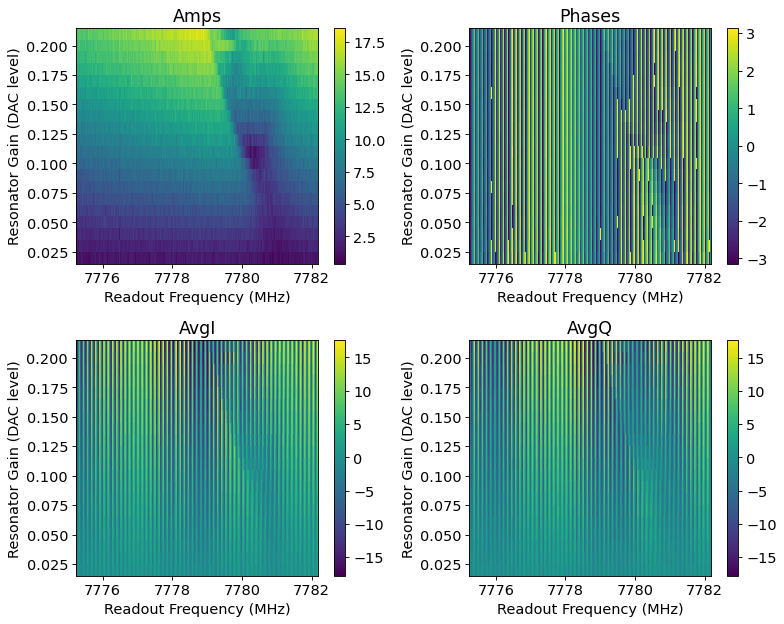

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 1604

High power peak [MHz]: 7779.2376
Low power peak [MHz]: 7780.7279
Lamb shift [MHz]: -1.4904


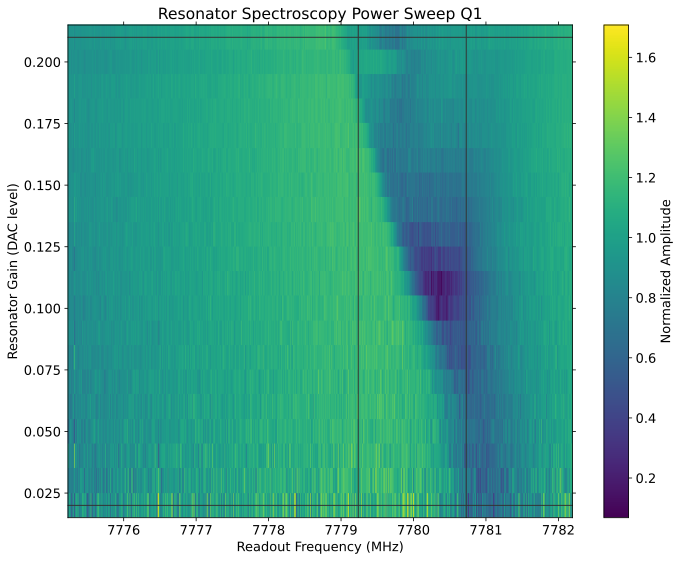

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

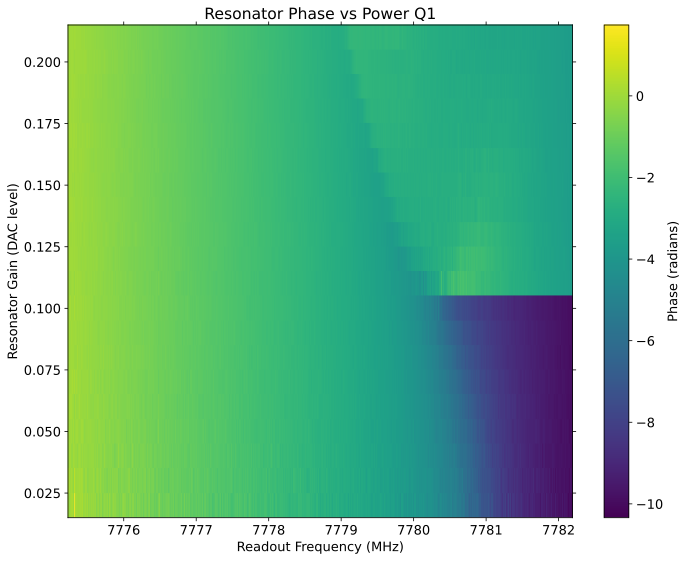

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

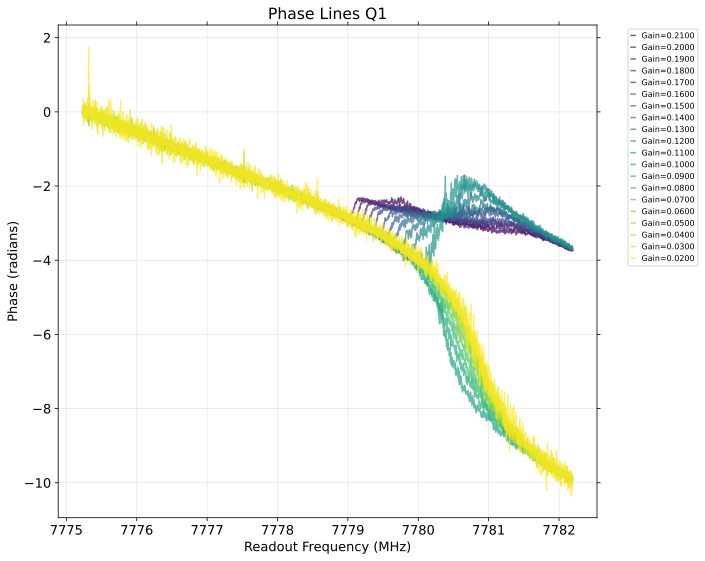

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

In [154]:
# f_off: center scan at res_freq - f_off

qi = 1
# auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
# rfboard.get_active_rf_state(auto_cfg)      


auto_cfg = config.load(cfg_path)

# params={'rng':100,'max_gain':1, 'span':40,"freq_offset":-10,'expts_gain':25,'expts':100,'reps':0.5} #buffer
params={'start_gain':0.02,'step_gain':0.01,'expts_gain':20,'span':7,'expts':2000,'reps':200,'log':False, "freq_offset":-1} #waste
# params={'rng':100,'max_gain':0.5, 'span':50,'expts_gain':10,'f_off':10,'expts':200,'reps':1} #waste:
rpowspec=meas.ResSpecPower(cfg_dict, qi=qi, params=params, live_plot=True)

In [ ]:
6682 - (114)**2/3.73

error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
error fitting
Gain Points	F0s
0.01	nan
0.02	nan
0.03	nan
0.04	nan
0.05	nan
0.060000000000000005	nan
0.06999999999999999	nan
0.08	nan
0.09	nan
0.09999999999999999	nan
0.11	nan
0.12	nan
0.13	nan
0.14	nan
0.15000000000000002	nan
0.16	nan
0.17	nan
0.18000000000000002	nan
0.19	nan
0.2	nan


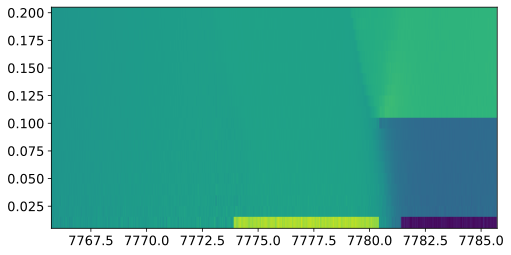

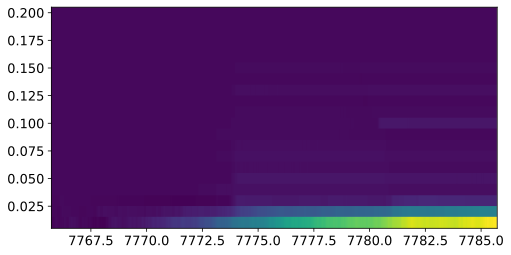

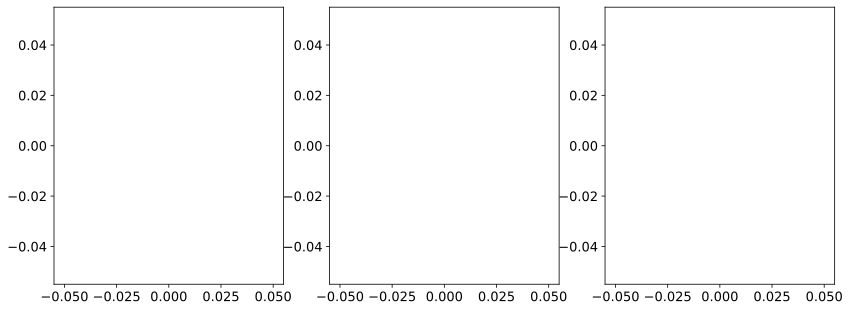

In [150]:
plt.pcolormesh(rpowspec.data['xpts'], rpowspec.data['gain_pts'], rpowspec.data['phases_corrected'], cmap="viridis", shading="auto", rasterized=True)

phases_corr = np.zeros_like(rpowspec.data['phases'])
f0s = []
kappas = []
kappa_cs = []
for i in range(rpowspec.data['gain_pts'].shape[0]):
    unwrapped = np.unwrap(rpowspec.data['phases'][i,:])
    polyfit = np.polyfit(rpowspec.data['xpts'][:200], unwrapped[:200], 1)
    unwrapped -= np.polyval(polyfit, rpowspec.data['xpts'])
    phases_corr[i,:] = unwrapped

    IQ = rpowspec.data['amps'][i,:]*np.exp(1j*unwrapped)
    try:
        popt = fitres.finefit(rpowspec.data['xpts'], IQ, [7742],p0=[0,0,0])
        if popt[0] > 7740:
            f0s.append(popt[0])
            kappas.append(popt[0]/popt[1])
            kappa_cs.append(popt[0]/popt[6]/2)
        else:
            print('fit failed, resonance frequency too far from expected value')
            f0s.append(np.nan)
            kappas.append(np.nan)
            kappa_cs.append(np.nan)
    except:
        print('error fitting')
        f0s.append(np.nan)
        kappas.append(np.nan)
        kappa_cs.append(np.nan)
        pass
    

    if rpowspec.data['gain_pts'][i] == 0.0086:
        plt.figure()
        plt.plot(IQ.real, IQ.imag, 'o-')
        plt.plot(fitres.resfunc3(rpowspec.data['xpts'], *popt[:6]).real, fitres.resfunc3(rpowspec.data['xpts'], *popt[:6]).imag, 'r-')
        fr_idx = np.argmin(abs(rpowspec.data['xpts']-popt[0]))
        
        plt.plot(fitres.resfunc3(popt[0], *popt[:6]).real, fitres.resfunc3(popt[0], *popt[:6]).imag, 'rx', label='fit at fr')
        plt.legend()

        plt.axis('equal')

plt.figure()
plt.pcolormesh(rpowspec.data['xpts'], rpowspec.data['gain_pts'], phases_corr, cmap="viridis", shading="auto", rasterized=True)
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(14,5))
ax[0].plot(rpowspec.data['gain_pts'], f0s, 'o-')
ax[1].plot(rpowspec.data['gain_pts'], kappas, 'o-')
ax[2].plot(rpowspec.data['gain_pts'], kappa_cs, 'o-')

#print gain points with f0s as rows in a table format for easy copying into excel, with gain points as the first column and f0s as the second column
print("Gain Points\tF0s")
for gain, f0 in zip(rpowspec.data['gain_pts'], f0s):
    print(f"{gain}\t{f0}")

# plt.xlim([0.01,0.0125])

# Qubit Spectroscopy

In [ ]:
##Power sweep
qi = 1
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
rfboard.get_active_rf_state(auto_cfg)      

# params={'start':3700,'span':200,'expts':300}
#qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', params=params)
qspec_pow = meas.QubitSpecPower(cfg_dict, qi=qi, style='', 
                                params={'start':4100,
                                        'span':50,
                                        'rng': 100,
                                        'reps':50,
                                        'rounds':1,
                                        'expts':500,
                                        'expts_gain':20, 
                                        'max_gain':1, 
                                        'length':10,'sep_readout':True})

In [ ]:
update=True

qi = 1
# auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
# rfboard.get_active_rf_state(auto_cfg)      


auto_cfg = config.load(cfg_path)

# Default params, just specify style 
#qspec=meas.QubitSpec(cfg_dict, qi=qi, style='huge')

# Different examples of params you might give; frequency can be specified as start and span or if no start given, center is f_ge from config
#qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse', params={'span':500,'start':3000, 'expts':1000, 'gain':0.2})
#params={'start':3825, 'span':1000, 'gain':1, 'expts':1000}
#params={'span':50,'expts':200,'gain':0.06,'sep_readout':True, 'length':3, 'readout_length':10, 'reps':10000}
params={'span':18,'expts':200,'gain':0.001,'reps':2000,'length':50, 'readout_length':4,'sep_readout':True}

qspec=meas.QubitSpec(cfg_dict, qi=qi, style='fine', params=params)
if update and qspec.status: 
    auto_cfg = config.update_qubit(cfg_path, 'f_ge', qspec.data["best_fit"][2], qi)
    auto_cfg = config.update_qubit(cfg_path, 'kappa',qspec.data["best_fit"][3], qi)
elif update:
    print(f'Bad qubit! qi={qi}')

In [ ]:
# You may want to update this frequency, which will be the center of the scan. 
#style huge, coarse, medium, fine 
update=True

# qubit_list = np.arange(3)
qubit_list=[1]
for qi in qubit_list:
    qspec=meas.QubitSpec(cfg_dict, qi=qi, style='medium', params={'checkEF':True,'gain':0.01, 'span':20,'length':50,'reps':5000,'expts':70})
    #qspec=meas.QubitSpec(cfg_dict, qi=qi, style='coarse', params={'checkEF':True, 'reps':750,'gain':0.15, 'span':200})

    #qspec=meas.QubitSpec(cfg_dict, qi=qi, style='medium', params={'checkEF':True})#, params={'span':500, 'expts':1000,'reps':500,'gain':0.2})
    if update and qspec.status:
        auto_cfg = config.update_qubit(cfg_path, 'f_ef', qspec.data["best_fit"][2], qi)

In [ ]:
qubit_list=[1]
# Setting number of rounds multiplies the default number of rounds by that number, so can be greater than or less than 1. 
# Make sure to run single shot first 
for qi in qubit_list: 
    # rounds will make scan take longer, needed for lower temperatures. 
    temp, pop,_,_ = measure_func.measure_temp(cfg_dict, qi=qi, temp=60)# , rounds=5)
    auto_cfg = config.update_qubit(cfg_path, 'temp', temp, qi)
    auto_cfg = config.update_qubit(cfg_path, 'pop', pop, qi)

# Rabi

In [ ]:
auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
rfboard.get_active_rf_state(auto_cfg)      

In [ ]:
qubit_list = [1]


update=True

for qi in qubit_list: 
    #amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi)#, disp_kwargs={'show_hist':True})
    
    # Fully customized version
    # amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, 
    #                                params={'reps':2000,
    #                                        'pulse_type':'gauss',
    #                                        'expts':100})
    params = {'reps':2000,}
    amp_rabi = meas.RabiExperiment(cfg_dict,qi=qi, params=params)
    if update and amp_rabi.status:
        config.update_qubit(cfg_path, ('pulses','pi_ge','gain'), amp_rabi.data['pi_length'], qi) 

# T1

If it's the first time, also set T2r and T2e as guesses 


  0%|          | 0/13500 [00:00<?, ?it/s]

R2:0.943	Fit par error:0.069	 Best fit:b'avgi'


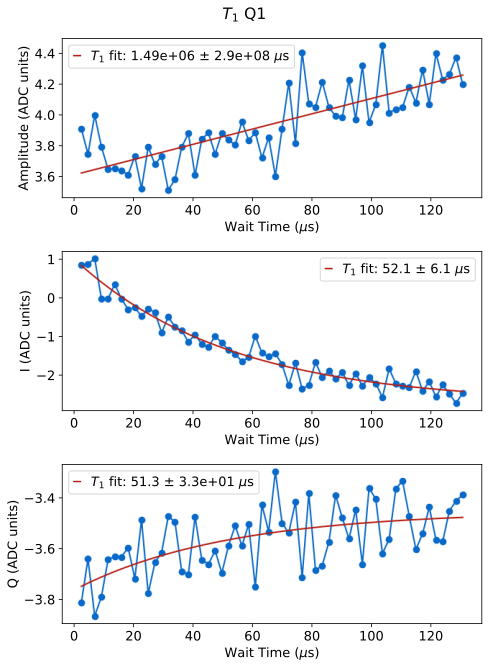

*Set cfg device.qubit 1 T1 to 52.14 from 35.89*
*Set cfg device.readout 1 final_delay to 312.83 from 215.33*


In [140]:
update=True
first_time=False

qubit_list = np.arange(1)
qubit_list=[1]
for qi in qubit_list:
    t1 = meas.T1Experiment(cfg_dict, qi=qi)#, params={'reps':2000})
    #t1 = meas.T1Experiment(cfg_dict, qi=qi, params={'reps':1000,'span':0, 'start':20})
    #t1 = meas.T1Experiment(cfg_dict, qi=qi, disp_kwargs={'show_hist':True})

    if update: t1.update(first_time=first_time)

In [ ]:
t2 = meas.T2Experiment(cfg_dict,qi=qi, params={'active_reset':True})
t22 = meas.T2Experiment(cfg_dict,qi=qi, params={'active_reset':False})

plt.figure()
plt.plot(t2.data['xpts'], t2.data['avgi'], label='Active Reset')
plt.plot(t22.data['xpts'], t22.data['avgi'])
plt.legend()
# plt.figure()
# plt.plot(t2.data['xpts'], t2.data['avgq'])
# plt.plot(t22.data['xpts'], t22.data['avgq'])

# histograms are different for active reset vs no active reset!!! because it's getting the full set of measured data. you should adjust to the first one. 
plt.figure()
plt.plot(t2.data['bin_centers'], t2.data['hist'])
plt.plot(t22.data['bin_centers'], t22.data['hist'])

# Stark calibration

In [ ]:
rfboard.get_active_rf_state(auto_cfg)   # this channel only



In [ ]:
soc.rfb_set_gen_rf(9, 0, 20)   # channel 9 directly

In [ ]:
# qi=0
params={'df_stark':0, 'max_stark_gain':1,'min_stark_gain':0.003, 'df':-10,'span':30, 'stark_expts':100,"length":10,"stark_length":25, 'reps':200,"final_delay":500,'stark_qubit':0,'stark_chan':9}
stark_spec=meas.StarkSpec(cfg_dict, qi=1, style='medium', params=params)

n_photon_conversion = stark_spec.data['n']

# 4WM

In [ ]:
4133.2384 + 7780.882 - 6682.6605

In [ ]:
soc.rfb_set_gen_filter(3, fc=4.3, bw=0.5, ftype="bandpass")   # DAC/generator side
# soc.rfb_set_gen_rf(3, 0, 10)   # channel 9 directly

In [ ]:
params={'span':100,'expts':100,'reps':500,'length_p':30,'start': 5140, 'frequency_b': 6682.6605, 'gain_b':0.5,'length_b':30,'sep_readout':True,'start_gain':0.001,'step_gain':0.005,'expts_gain':190,'log':False,'do_buffer':True}
data = meas.QubitSpecShotPower(cfg_dict, qi=1,params=params)

plt.pcolormesh(data.data['xpts'], data.data['ypts'], data.data['p_e'], shading='auto')
plt.xlabel('Gain')
plt.ylabel('Frequency')
plt.title('4WM Spectroscopy')
plt.colorbar(label='Excited State Probability')
plt.show()


In [ ]:
# import h5 data
import h5py

# load up most recent power spectroscopy data
files = os.listdir(expt_path + "\\data\\")
file = sorted([f for f in files if f.startswith('qubit_spectroscopy_power')])[-1]  # Get the most recent file
with h5py.File(expt_path + "\\data\\" + file, "r") as f:
    # List all groups
    print("Keys: %s" % f.keys())
    p_e = f['p_e'][:]
    xpts = f['xpts'][:]
    gain_p_pts = f['gain_p_pts'][:]



max_indices = np.argmax(p_e, axis=1)
# plt.plot(xpts[max_indices][10:], gain_p_pts[10:], 'o-', label='Max P(e)', color='red')
# plt.legend()


plt.figure()
max_p_e = np.max(p_e, axis=1)
fwm_start = 20
plt.plot(gain_p_pts[fwm_start:], max_p_e[fwm_start:], 'o-', label='Max P(e)', color='red')
plt.xlabel("Pump Gain (DAC units)")
plt.ylabel("Max Excited State Probability")
plt.legend()

# frequency at which max p_e occurs vs gain

freq_devs = ( xpts[max_indices][fwm_start:])

#fit a parabola to freq_devs vs gain_p_pts
from scipy.optimize import curve_fit
def cubic(x, a, c, a3):
    # force parabola to open upwards and have vertex at 0 by setting b=0 and c=0
    return a3*x**3 + a*x**2 + c
popt, pcov = curve_fit(cubic, gain_p_pts[fwm_start:], freq_devs)


plt.figure()
plt.plot(gain_p_pts[fwm_start:], freq_devs , 'o-', label='Frequency at Max P(e)', color='green')
plt.plot(gain_p_pts, cubic(gain_p_pts, *popt), label='Cubic Fit', color='orange')
plt.xlabel("Pump Gain (DAC units)")
plt.ylabel("Pump Frequency at Max P(e) (MHz)")
plt.legend()

print(f"Fitted cubic parameters: a={popt[0]:.3e}, c={popt[1]:.3f} MHz, a3={popt[2]:.3e}")

#print out pump frequency along the cubic where gain = 0.3
target_gain = 0.59
target_freq = cubic(target_gain, *popt)
print(f"Pump frequency at gain {target_gain}: {target_freq:.2f} MHz")   

#find nearest pump_frequency points to the best fit parabola at all the gain_p_pts
best_fit_freqs = cubic(gain_p_pts, *popt)

plt.figure()
plt.pcolormesh(xpts, gain_p_pts, p_e, shading='auto')
plt.ylabel("Pump Gain (DAC units)")
plt.xlabel("Pump Frequency (MHz)")
plt.colorbar(label="Excited State Probability")
#plot the best fit cubic on top
plt.plot(best_fit_freqs, gain_p_pts, label='Best Fit Cubic', color='orange')
plt.tight_layout()
plt.savefig(expt_path + "\\images\\summary\\4WM_spec_power.png", dpi=200)


# iterate through the gain_p_pts and find the nearest xpts to the best fit cubic, then plot the p_e vs xpts for those gain_p_pts
plt.figure()
for i, gain in enumerate(gain_p_pts):
    best_freq = cubic(gain, *popt)
    nearest_freq_idx = np.argmin(np.abs(xpts - best_freq))
    # plt.plot(xpts, p_e[i,:], label=f'Gain {gain:.3f}')
    plt.plot(gain, p_e[i, nearest_freq_idx], 'o', color='black')  # mark the nearest point
plt.grid(True)
plt.xlabel("Pump Gain (DAC units)")
plt.title("Excited State Probability at Best Fit Frequency")
plt.ylabel("p(e)")
plt.ylim(0,1)
plt.tight_layout()
plt.savefig(expt_path + "\\images\\summary\\4WM_spec_power_cubic_points.png", dpi=200)

# find the frequency along the cubic where gain = 0.25, then plot the p_e vs gain at that frequency
target_gain = 0.35
target_freq = cubic(target_gain, *popt)
nearest_freq_idx = np.argmin(np.abs(xpts - target_freq))
plt.figure()
plt.plot(gain_p_pts, p_e[:, nearest_freq_idx], 'o-', label=f'P(e) at freq={target_freq:.2f} MHz', color='purple')
plt.title(f'pump gain = {target_gain:.2f}')
plt.xlabel("Pump Gain (DAC units)") 
plt.ylabel("Excited State Probability")
plt.legend()

In [ ]:
params={'reps':5000,'gain_p':0.25,'length_p':10,'start': 5200, 'span':50,'expts':50, 'center_freq_b': 6680, 'expts_b':50,'gain_b':0.01, 'span_b':20,'length_b':10,'delay_b':0,'sep_readout':True}
data = meas.QubitSpecShotBuffer(cfg_dict, qi=1,params=params)

In [ ]:
# find peak p_e in the data, find the buffer frequency at that point
peak_p_e = np.max(data.data['p_e'])
peak_idx = np.unravel_index(np.argmax(data.data['p_e'], axis=None), data.data['p_e'].shape)
peak_freq = data.data['ypts'][peak_idx[1]]
print(f"Peak p(e) = {peak_p_e:.3f} at frequency {peak_freq:.2f} MHz")

In [ ]:
gainb_tb_sweeps = []

for gain_p in np.arange(0.0,0.8,0.025):
    frequency_p = cubic(0.25,*popt)

    gainb_tb_sweep = meas.FWM_gainb_tb_sweep(cfg_dict, qi=1, params={'gain_p':gain_p,'frequency_p':frequency_p,'length_p':50,'start':0.001,'span':0.08,'expts':100,'frequency_b':6917.25,'reps':1000,'length_b_start':0.1,'length_b_end':50,'length_b_expts':100,'save_shots':True}, display=True)

    clear_output(wait=True)
    plt.pcolormesh(gainb_tb_sweep.data['xpts'], gainb_tb_sweep.data['ypts'], gainb_tb_sweep.data['p_e'])
    plt.xlabel('buffer gain')
    plt.ylabel('buffer length (us)')
    plt.title(f'Pump Gain = {gain_p:.3f}')
    plt.colorbar(label=r'$p_e$')
    plt.show()

    gainb_tb_sweeps.append(gainb_tb_sweep)

# Single Shot

Activated qubit 1: ADC ch 1 (fc=8200, bw=100, bandpass), DAC-ro ch 1 (fc=8200, bw=100, bandpass), DAC-qb ch 3 (fc=4300, bw=500, bandpass), DC bias ch 1 (val=0.03 V)


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

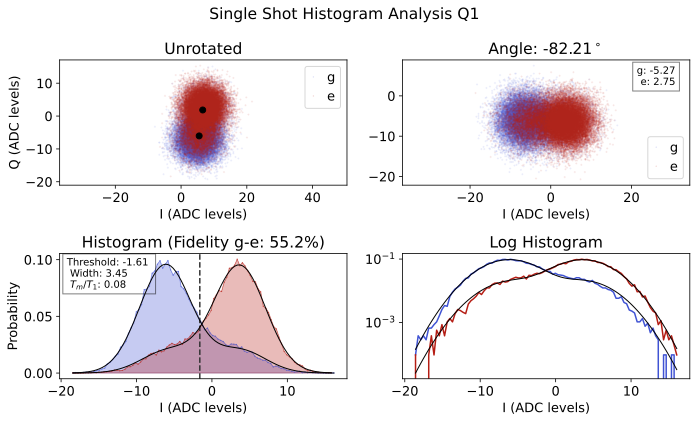

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

*Set cfg device.readout 1 phase to -82.2091 from -71.9399*
*Set cfg device.readout 1 threshold to -1.6072 from -1.5207*
*Set cfg device.readout 1 fidelity to 0.5518 from 0.5063*
*Set cfg device.readout 1 g_mean to -4.4933 from -4.1758*
*Set cfg device.readout 1 e_mean to 2.0386 from 1.9077*
*Set cfg device.readout 1 sigma to 3.4453 from 3.4965*
*Set cfg device.readout 1 tm to 0.0775 from 0.0*
*Set cfg device.qubit 1 tuned_up to True from True*


In [168]:
qubit_list=[1]
for qi in qubit_list:
    auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)
    shot = meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':30000,'active_reset':False, 'setup_reset':False,'remeas':False})
    shot.update()
    #shot.check_reset()
    #config.update_readout(cfg_path, 'reset_e', shot.data['reset_e'], qi)
    #config.update_readout(cfg_path, 'reset_g', shot.data['reset_g'], qi)

In [ ]:
shot.data

Band-pass set: fc=7650.0 MHz, bw=100.0 MHz (edges 7600.0–7700.0 MHz). gen_ch=1, ro_ch=1


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

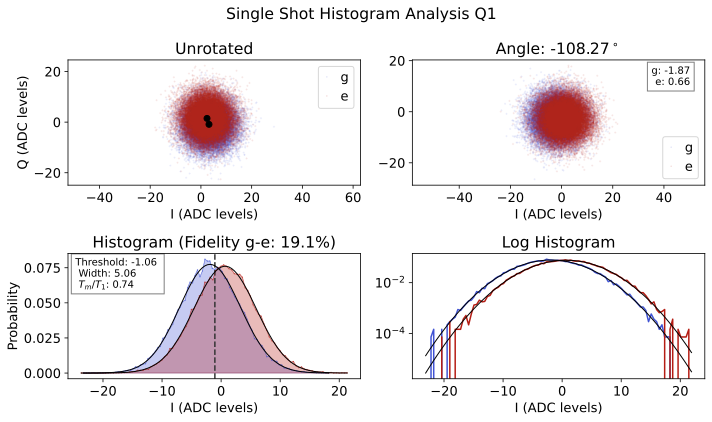

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

Band-pass set: fc=7862.5 MHz, bw=100.0 MHz (edges 7812.5–7912.5 MHz). gen_ch=1, ro_ch=1


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

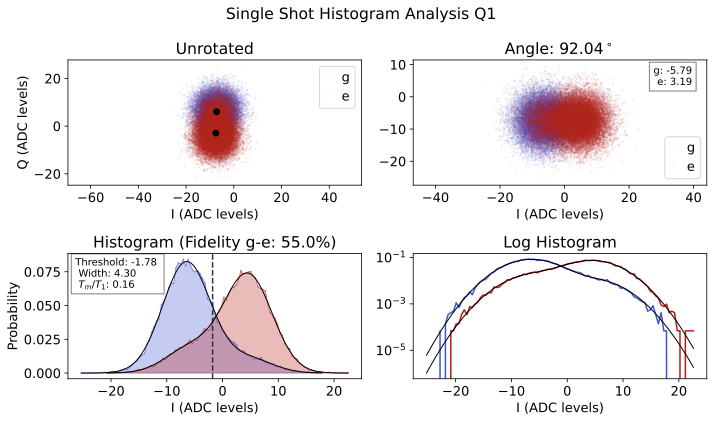

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

Band-pass set: fc=8075.0 MHz, bw=100.0 MHz (edges 8025.0–8125.0 MHz). gen_ch=1, ro_ch=1


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

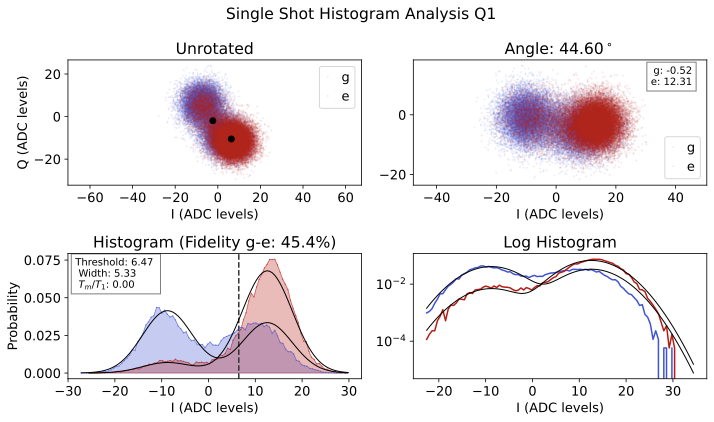

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

Band-pass set: fc=8287.5 MHz, bw=100.0 MHz (edges 8237.5–8337.5 MHz). gen_ch=1, ro_ch=1


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

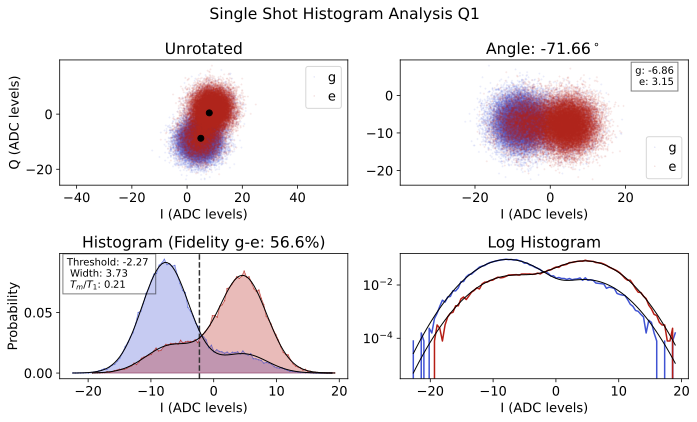

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

Band-pass set: fc=8500.0 MHz, bw=100.0 MHz (edges 8450.0–8550.0 MHz). gen_ch=1, ro_ch=1


  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

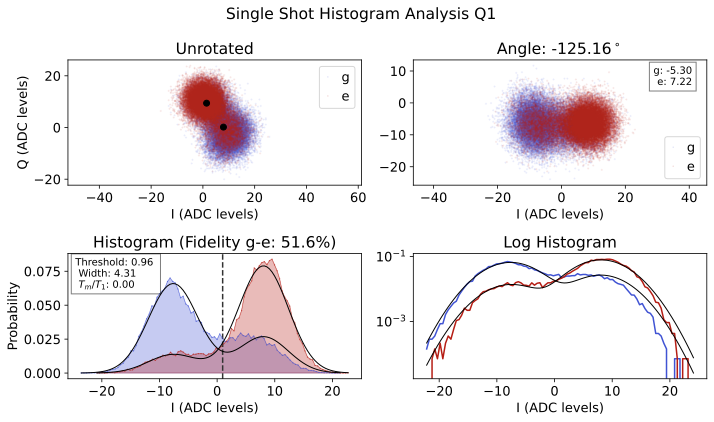

 C:\_Lib\python\slab_qick_calib\experiments\general\qick_experiment.py: 761

In [146]:
shots2d=[]
bw=100

freqs = np.linspace(7650, 8500, 5)
atts= [2]
for att in atts:
    shots=[]
    for fc in freqs:   
        rfboard.set_bandpass_rf(soc, qi, qi, fc, bw, ro_att=att)  
        shot = meas.HistogramExperiment(cfg_dict, qi=qi, params={'shots':30000})
        shots.append(shot.data)
    shots2d.append(shots)
    


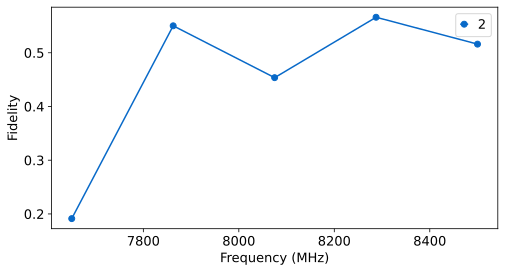

In [148]:
plt.figure()
plt.xlabel('Frequency (MHz)')
plt.ylabel('Fidelity')

for att, shots in zip(atts, shots2d):
    fid = [shot['fids'][0] for shot in shots]
    plt.plot(freqs, fid, 'o-', label=att)
plt.legend()


In [ ]:
plt.figure()
plt.plot(freqs, att5,'.-')
plt.plot(freqs, att7,'.-')
plt.plot(freqs, att10,'.-')
plt.plot(freqs, att12p5,'.-')
plt.plot(freqs, att15,'.-')
plt.plot(freqs, att20,'.-')

plt.xlabel(' Center Frequency (MHz)')
plt.ylabel('Fidelity')
plt.title('Qubit Tuning')
plt.show()
[shot['fids'][0] for shot in shots]

In [ ]:
shots[0]['fids']

### General sweep

Runs single shot experiments for many readout lengths, frequencies, gains and compares fidelity

low_gain=True chooses lowest gain/readout length within a few percent of maximum gain (often readout fidelity fairly flat as a function of gain at higher gain values) 

style='fine' varies parameters by 20%, style='' varies by 2x

In [ ]:
import importlib
importlib.reload(meas)

Activated qubit 1: ADC ch 1 (fc=8200, bw=100, bandpass), DAC-ro ch 1 (fc=8200, bw=100, bandpass), DAC-qb ch 3 (fc=4300, bw=500, bandpass), DC bias ch 1 (val=0.03 V)
Unexpected parameters found in params: {'step_len', 'step_f', 'step_gain'}


  0%|          | 0/5 [00:00<?, ?it/s]

Max fidelity 58.248 %
Optimal params: 
 Freq (MHz) 7779.732 
 Gain (DAC units) 0.138 
 Readout length (us) 11.946
Set fidelity: 56.698 %
Set params: 
 Freq (MHz) 7779.732 
 Gain (DAC units) 0.138 
 Readout length (us) 10.951


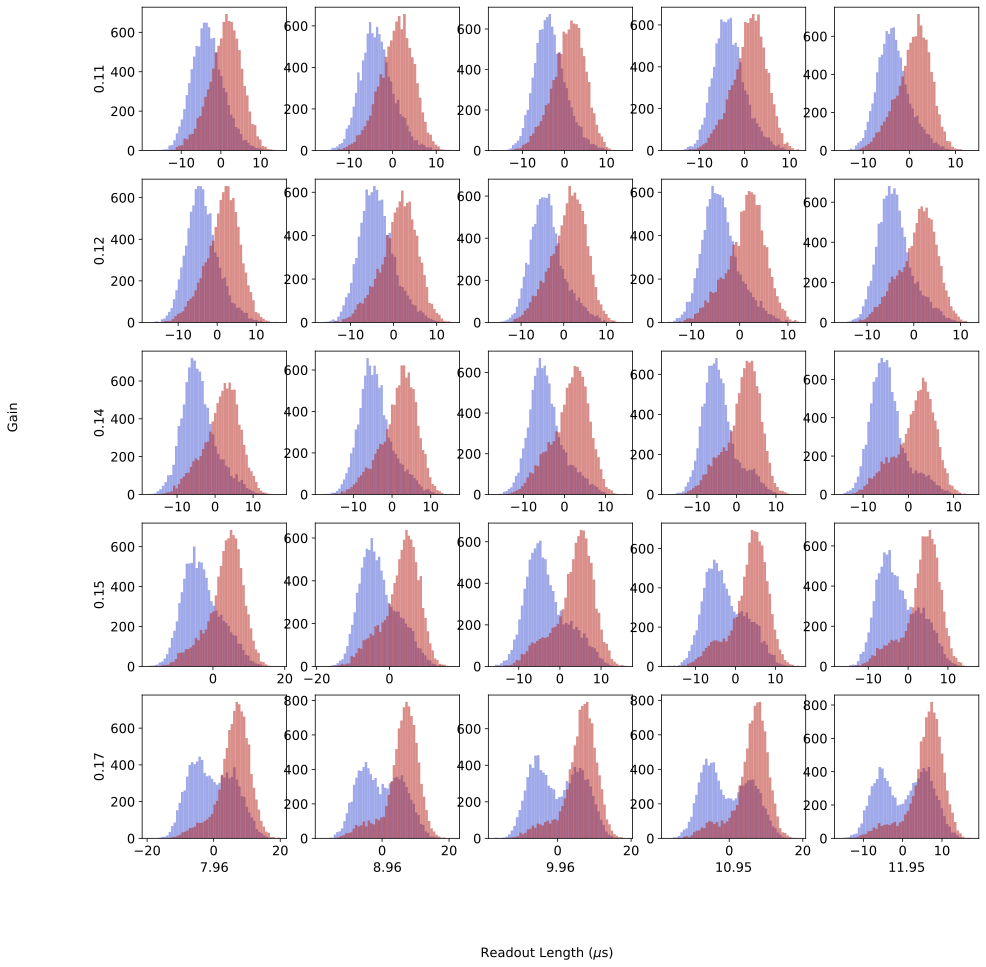

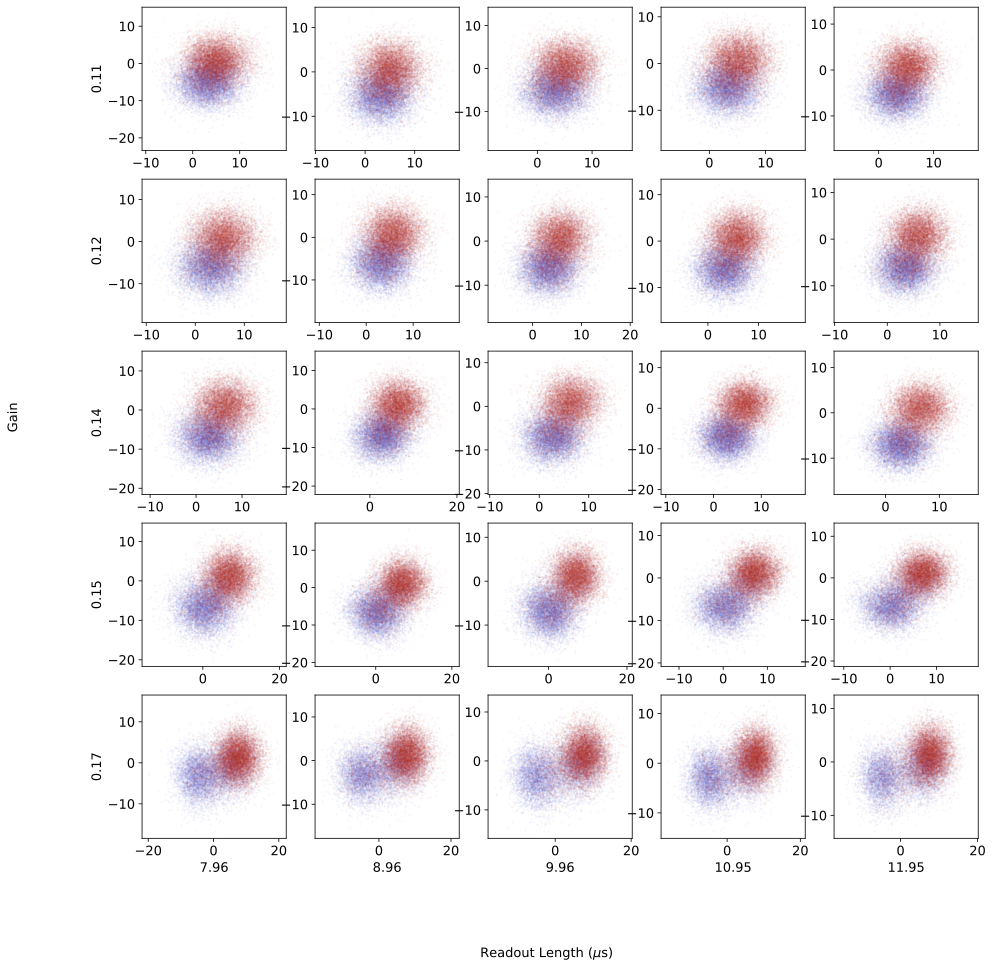

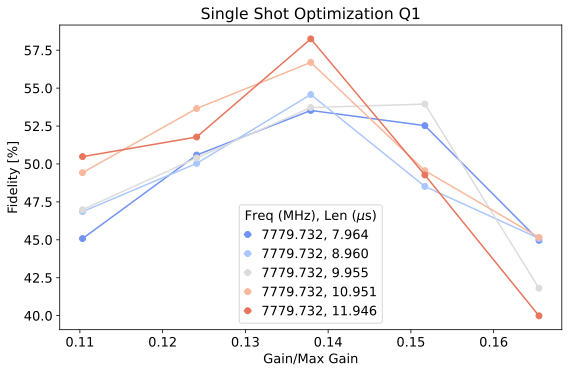

Max fidelity 58.248 %
Optimal params: 
 Freq (MHz) 7779.732 
 Gain (DAC units) 0.138 
 Readout length (us) 11.946
Set fidelity: 56.698 %
Set params: 
 Freq (MHz) 7779.732 
 Gain (DAC units) 0.138 
 Readout length (us) 10.951
*Set cfg device.readout 1 gain to 0.1379 from 0.1379*
*Set cfg device.readout 1 readout_length to 10.9506 from 9.9551*
*Set cfg device.readout 1 frequency to 7779.7324 from 7779.7324*


In [ ]:
update=True
low_gain=True

qubit_list=np.arange(1,6)
qubit_list=[1]

#params = {'expts_f':1, 'expts_gain':10, 'expts_len':10,'shots':10000}
#params = {'expts_f':1, 'expts_gain':10, 'expts_len':1}
params = {'expts_f':10, 'expts_len':1,'expts_gain':5,'shots':10000}
#params = {'expts_f':1, 'expts_gain':5, 'expts_len':5,'shots':10000}

# Specify exact ranges to use  
#params = {'expts_f':1, 'expts_gain':9, 'expts_len':9,'start_gain':0.45, 'span_gain':0.05,'start_len':2, 'span_len':5}

for qi in qubit_list: 
    auto_cfg = rfboard.activate_qubit_rf(qi, soc, auto_cfg, cfg_file=cfg_path)

    shotopt=meas.SingleShotOptExperiment(cfg_dict, qi=qi,params=params, display=True, style='fine')
    shotopt.analyze(low_gain=low_gain)
    if update: shotopt.update(cfg_dict['cfg_file'])

    #shot=meas.HistogramExperiment(cfg_dict, qi=qi)
    #shot.update()

In [ ]:
# 4WM Histogram
qi=1
#fwmhist = meas.SMPDHistogramExperiment(cfg_dict, qi=qi,params={'seq_mode': 'pi', 'shots':20000})
params = {
    "shots": 100000,
    "seq_mode": "4wm",       # Set to "4wm" to use the pump/buffer sequence, or "pi" for standard pi pulse
    "delay_b": 0,          # Buffer delay (in microseconds) after the pump pulse starts
    "active_reset": True,   # Set to True if you want to use active reset
    "check_f": False,        # Whether to measure the f-state
    "reset":2,
    # You can optionally override specific pulse parameters directly here instead of using the YAML config:
    "f_b": 6917.25,         # Buffer frequency
    "t_b": 10,            # Buffer length
    "gain_b": 0.01,         # Buffer gain
    "f_p": 5164.54,         # Pump frequency
    "t_p": 10,            # Pump length
    "gain_p": 0.59,         # Pump gain
    #"f_r": 6500.0,         # Waste/Readout frequency
    # "t_r": 2.0,            # Waste/Readout length
    # "gain_r": 0.5,         # Waste/Readout gain
}
fwmhist = meas.SMPDHistogramExperiment(cfg_dict, qi=qi,params=params)

In [ ]:
# loop through files in C:\_Data\SMPD\2026_04_11_v2_calibration\data
gainb_tb_sweeps = []
for file in os.listdir('C:\\_Data\\SMPD\\2026_04_11_v2_calibration\\data'):
    if 'lengthb_gainb' in file and not '00001' in file and not '00000' in file:
        gainb_tb_sweeps.append(file)
print(gainb_tb_sweeps)

In [ ]:
# for each buffer length, fit for the slope of p_e vs gain_b between 0.005 and 0.010 and plot it as a function of buffer length

pump_amplitudes = np.arange(0.1,0.8,0.025)
peak_efficiencies = []
for i in range(len(gainb_tb_sweeps)):
    print('===============================')
    print('doing pump amplitude: {:.3f}'.format(pump_amplitudes[i]))

    gainb_tb_sweep = gainb_tb_sweeps[i]
    fig,ax = plt.subplots(figsize=(6,4),nrows=1,ncols=2)
    slopes = []
    highlighted_lengths = [1,2,5,10,20,50]
    idcs = []
    for length in highlighted_lengths:
        #find the right index in gainb_tb_sweep.data['ypts'] that corresponds to this length
        idx = np.argmin(np.abs(gainb_tb_sweep.data['ypts'] - length))
        idcs.append(idx)


    for i in range(gainb_tb_sweep.data['ypts'].shape[0]):
        p_e_slice = gainb_tb_sweep.data['p_e'][i,:]
        # convert gain_b to 1-P(0) using the same conversion as before
        gain_b_slice = gainb_tb_sweep.data['xpts']

        # plot p_e_slice vs gain_b_slice for some characteristic buffer length values to see how the slope changes with buffer length
        if i in idcs:
            ax[0].plot(gain_b_slice, p_e_slice)
            # draw a line at one photon gain for reference
            one_photon_gain = np.sqrt(1/n_photon_conversion)
            ax[0].axvline(one_photon_gain, color='red', linestyle='--')
            ax[0].set_xlabel('buffer gain')
            ax[0].set_ylabel('p_e')

        n_photons = gain_b_slice**2 * n_photon_conversion
        poisson_zero = poisson.pmf(0, n_photons)
        gain_b_slice = 1 - poisson_zero

        if i in idcs:
            ax[1].plot(gain_b_slice, p_e_slice, label=f'buffer length: {gainb_tb_sweep.data["ypts"][i]:.1f} us')
            # draw a line at one photon gain for reference


        # find indices corresponding to 1-P(0) of 0.05 and 0.2
        idx_05 = np.argmin(np.abs(gain_b_slice - 0.05))
        idx_02 = np.argmin(np.abs(gain_b_slice - 0.2))


        # fit for slope between these two points
        p_e_slice = p_e_slice[idx_05:idx_02]
        gain_b_slice = gain_b_slice[idx_05:idx_02]
        # fit a linear function to the data
        coeffs = np.polyfit(gain_b_slice, p_e_slice, 1)
        slope = coeffs[0]
        slopes.append(slope)

    one_photon_gain = 1 - poisson.pmf(0, 1)
    ax[1].axvline(one_photon_gain, color='red', linestyle='--',label='one photon gain')
    ax[1].set_xlabel('1-P(0)')

    # put legend to the right of the plot
    plt.legend(bbox_to_anchor=(1.05, 1))

    # fit slope data to a product of two exponentials of the form A*(B-exp(-x/tau1))*(exp(-x/tau2)+C) and plot the fit



    plt.figure()
    plt.plot(gainb_tb_sweep.data['ypts'], slopes)
    try: 
        def fit_func(x, A, B, tau1, tau2, C):
            return A*(B-np.exp(-x/tau1))*(np.exp(-x/tau2)+C)
        from scipy.optimize import curve_fit
        lb = [0,0,0,0,0]
        ub = [100,100,100,100,100]
        popt, pcov = curve_fit(fit_func, gainb_tb_sweep.data['ypts'], slopes, p0=[0.5, 1, 0.2, 20, 0.1])
        plt.plot(gainb_tb_sweep.data['ypts'], fit_func(gainb_tb_sweep.data['ypts'], *popt), label=f'kb={1/popt[2]*(2*np.pi):.2f} MHz, T1={popt[3]:.2f} us', color='orange')
        #plot the individual exponential components of the fit
        plt.plot(gainb_tb_sweep.data['ypts'], popt[0]*(popt[1]-np.exp(-gainb_tb_sweep.data['ypts']/popt[2])), label='kb component', color='green')
        plt.plot(gainb_tb_sweep.data['ypts'], popt[0]*(np.exp(-gainb_tb_sweep.data['ypts']/popt[3])+popt[4]), label='T1 component', color='red')

        #show the functional form of the fit as an equation off to the side of the plot using plt.text
        plt.text(1.1, 0.5, f'$A(B-e^{{-x/\\tau_1}})(e^{{-x/\\tau_2}}+C)$\nA={popt[0]:.2f}\nB={popt[1]:.2f}\n$\\tau_1$={popt[2]:.2f} us\n$\\tau_2$={popt[3]:.2f} us\nC={popt[4]:.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='center', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

        peak_efficiencies.append(max(fit_func(gainb_tb_sweep.data['ypts'],*popt)))

    except:
        print('error fitting')
        peak_efficiencies.append(None)
        pass
    plt.xlabel('buffer length (us)')
    plt.ylabel('efficiency')
    plt.ylim(-0.05, 1.5)
    plt.legend()
    plt.show()

    print(' ')
    print('  ')
